**Filter genes by rank product**

Author: Ella Chee

Date: October 2024

Description: Analyze results from BETA (binding and expression target analysis)

In [1]:
# Imports
import pandas as pd

In [2]:
# Read in 01hr uptargeted genes
one_hr = pd.read_csv('./direct-target-predictions/plus_01hr_uptarget.bed', sep='\t')

In [3]:
# Set threshold to 0.001 for rank product (use as p-value)
one_hr_cutoff = one_hr[one_hr['rank product'] <= 1e-3]

In [4]:
one_hr_cutoff.head()

,Chroms,txStart,txEnd,refseqID,rank product,Strands,GeneSymbol
0,chr19,40928408,40931932,NM_013376,0.000002,-,SERTAD1
1,chr1,203274663,203278729,NM_006763,0.000022,+,BTG2
2,chr19,59073283,59084942,NM_001267033,0.000023,-,MZF1
3,chr17,8043787,8055753,NM_002616,0.000025,-,PER1
4,chr19,40946747,40948505,NM_013368,0.000027,-,SERTAD3


In [11]:
len(one_hr_cutoff)

112

In [5]:
# Read in/threshold values for 24hr and 48hr
twenty_four_hr = pd.read_csv('./direct-target-predictions/plus_24hr_uptarget.bed', sep='\t')
forty_eight_hr = pd.read_csv('./direct-target-predictions/plus_48hr_uptarget.bed', sep='\t')

# To generate cutoff dataframe
def cutoff(df):
    cutoff_df = df[df['rank product'] <= 1e-3]
    return cutoff_df

twenty_four_hr_cutoff = cutoff(twenty_four_hr)
forty_eight_hr_cutoff = cutoff(forty_eight_hr)

# Sanity check for values
print('24hr:', len(twenty_four_hr))
print('24hr cutoff:', len(twenty_four_hr_cutoff))
print('48hr:', len(forty_eight_hr))
print('48hr cutoff:', len(forty_eight_hr_cutoff))

24hr: 2548
24hr cutoff: 93
48hr: 2476
48hr cutoff: 88


In [6]:
# Generate 01hr downtarget genes
one_hr_downtarget = pd.read_csv('./direct-target-predictions/plus_01hr_downtarget.bed', sep='\t')
one_hr_downtarget_cutoff = cutoff(one_hr_downtarget)
print(len(one_hr_downtarget_cutoff))

86


In [51]:
one_hr_downtarget_cutoff.to_csv('filtered_01hr_downtarget.csv')

In [10]:
# Convert filtered values to CSVs
dfs = [one_hr_cutoff, twenty_four_hr_cutoff, forty_eight_hr_cutoff]
hrs = ['01hr', '24hr', '48hr']
count = 0
for df in dfs:
    df.to_csv('./filtered-target-predictions/filtered_'+hrs[count]+'_uptarget.bed', sep='\t')
    print(hrs[count], 'to bed')
    count+=1

01hr to bed
24hr to bed
48hr to bed


**Subset genes, represent upregulated genes across UV timepoints as venn diagram**

In [54]:
# Represent venn diagram
from venn import venn
import matplotlib.pyplot as plt

In [128]:
# Create sets of genes at each timepoint 
uptarget_01hr = set(one_hr_cutoff['GeneSymbol'])
uptarget_24hr = set(twenty_four_hr_cutoff['GeneSymbol'])
uptarget_48hr = set(forty_eight_hr_cutoff['GeneSymbol'])

gene_sets = {
    '01hr': uptarget_01hr, 
    '24hr': uptarget_24hr, 
    '48hr': uptarget_48hr}

In [129]:
# Get subsets/intersections of genes
uptarget_all = uptarget_01hr & uptarget_24hr & uptarget_48hr
uptarget_01hr_and_24hr = uptarget_01hr & uptarget_24hr - uptarget_all
uptarget_01hr_and_48hr = uptarget_01hr & uptarget_48hr - uptarget_all
uptarget_24hr_and_48hr = uptarget_24hr & uptarget_48hr - uptarget_all

only_uptarget_01hr = uptarget_01hr - uptarget_all - uptarget_01hr_and_24hr - uptarget_01hr_and_48hr
only_uptarget_24hr = uptarget_24hr - uptarget_all - uptarget_01hr_and_24hr - uptarget_24hr_and_48hr
only_uptarget_48hr = uptarget_48hr - uptarget_all - uptarget_01hr_and_48hr - uptarget_24hr_and_48hr


In [77]:
# To pad lists with none to get same-length lists
def pad_lists(*lists):
    max_length = max(len(lst) for lst in lists)
    return [lst + [None] * (max_length - len(lst)) for lst in lists]

# Pad gene lists
padded_lists = pad_lists(list(uptarget_01hr), list(uptarget_24hr), list(uptarget_48hr),
list(uptarget_all), list(uptarget_01hr_and_24hr), list(uptarget_01hr_and_48hr), list(uptarget_24hr_and_48hr))

# Data dictionsary containing each subset
data_dict = {
    'genes_01hr': padded_lists[0],
    'genes_24hr': padded_lists[1],
    'genes_48hr': padded_lists[2],
    'genes_all': padded_lists[3],
    'genes_01hr_and_24hr': padded_lists[4],
    'genes_01hr_and_48hr': padded_lists[5],
    'genes_24hr_and_48hr': padded_lists[6]
}

# Create dataframe of subsets
genes_df = pd.DataFrame(data_dict)
genes_df.head()

,genes_01hr,genes_24hr,genes_48hr,genes_all,genes_01hr_and_24hr,genes_01hr_and_48hr,genes_24hr_and_48hr
0,HBEGF,ZNF446,SREBF1,MUC1,TRAF4,PLEKHG2,JUP
1,PKD1,CRIP2,ABHD8,TLCD1,RHOF,ZNF837,CRIP2
2,MEX3B,DOK4,CRIP2,U2AF1L4,BTG2,NEK8,CCND3
3,CEBPA,GLDC,SERTAD3,SERTAD3,CLK2,ZNF703,PTPRU
4,CDK9,SERTAD3,PTOV1-AS2,PSME1,BBC3,RTN2,GPX2


In [78]:
# Convert dataframe to CSV containing gene subsets
genes_df.to_csv('uptargets_subsets.csv')

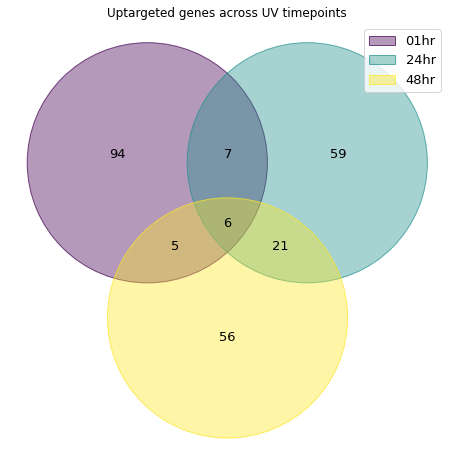

In [131]:
# Venn diagram of gene sets across timepoints
venn(gene_sets, fmt='{size}')
#plt.text(0.51,0.45, '\n'.join(uptarget_all))
#plt.text(0.46,0.68, '\n'.join(uptarget_01hr_and_24hr))
#plt.text(0.28,0.38, '\n'.join(uptarget_01hr_and_48hr))
#plt.text(0.65,0.1, '\n'.join(uptarget_24hr_and_48hr))
plt.title('Uptargeted genes across UV timepoints')
plt.autoscale()
plt.savefig('uptarget_genes.svg', format='svg')
plt.show()